# When Should a Memory System Ask the User?
### A transparent, human-controllable memory layer for LLM chatbots — demo and results

**Prem Prakash Agarwal (264161005)** · M.Tech Data Science, IIT Guwahati

This notebook:

1. **Demonstrates the memory pipeline offline**: conflict detection, history-keeping updates, deletion that really takes effect, and retrieval. It uses a scripted LLM, so no API key is needed.
2. Optionally runs the **live pipeline** with a real Groq model.
3. Shows **how to reproduce the LongMemEval evaluation**.
4. **Reproduces every result** in the report from the saved files in `results/`: accuracy, what happened at each update, every question the system asked the user (worth asking or not), error analysis, and cost.

### Setup
```bash
git clone <this repo> && cd memory-chat
pip install -r requirements.txt
cp .env.example .env          # add GROQ_API_KEY=... (only needed for Parts 2-3 and the app)
streamlit run app.py          # the interactive app
jupyter notebook demo_and_results.ipynb
```

In [1]:
import os, sys, json, re, time, sqlite3
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
print("project folder:", ROOT.name)
print("results files :", sorted(p.name for p in RESULTS.glob("*")))

project folder: repo
results files : ['qa_lme_decision.csv', 'summary_lme_decision.json', 'trace_lme_decision.md']


## Part 1 — Offline demo of the memory pipeline

The real app calls an LLM for two steps after every turn: **extraction** (candidate memories) and the **decision** (add / update / skip / conflict against the 5 most similar memories). Here a `ScriptedLLM` returns fixed answers for the decision step, so the storage, versioning, event log, conflict and context logic all run for real without an API key.

In [2]:
from database.schema import SCHEMA
from memory.store import MemoryStore
from memory.models import MemoryStatus
from strategies.baseline import BaselineStrategy

class ScriptedLLM:
    """Returns pre-written JSON answers, in order, instead of calling an API."""
    def __init__(self, answers): self.answers = list(answers)
    def json_completion(self, messages, **kw): return self.answers.pop(0)

def fresh_store():
    conn = sqlite3.connect(":memory:"); conn.row_factory = sqlite3.Row
    conn.executescript(SCHEMA)
    return MemoryStore(conn)

def show(store):
    for m in store.list(status=MemoryStatus.ACTIVE):
        print(f"  [v{m.version}] {m.content}")

### A. A contradiction becomes a question, and nothing is overwritten
The user said *"I study at IIT Guwahati"*, and later *"I'm at IIT Kanpur"*. The decision step reports a conflict, so the old memory stays untouched until the user picks a resolution.

In [3]:
store = fresh_store()
llm = ScriptedLLM([{"action": "conflict", "target": 1, "confidence": 0.9,
                    "reason": "Different college and no sign of a move",
                    "options": ["User studies at IIT Kanpur.",
                                "User previously studied at IIT Guwahati and now studies at IIT Kanpur."]}])
strategy = BaselineStrategy(store, llm=llm)

strategy.apply_candidates("demo", [{"content": "User studies at IIT Guwahati."}], source="turn 1")
events = strategy.apply_candidates("demo", [{"content": "User studies at IIT Kanpur."}], source="turn 2")

print("event raised:", events[0].type.value, "|", events[0].reason)
print("options shown to the user:", events[0].options)
print("memory while the question is pending:"); show(store)

strategy.resolve_conflict(events[0].id, events[0].options[1])   # the user clicks option 2
print("after the user's choice:"); show(store)
print("version history:", [v.content for v in store.version_history(events[0].memory_id)])

event raised: conflict | Different college and no sign of a move
options shown to the user: ['User studies at IIT Kanpur.', 'User previously studied at IIT Guwahati and now studies at IIT Kanpur.']
memory while the question is pending:
  [v1] User studies at IIT Guwahati.
after the user's choice:
  [v2] User previously studied at IIT Guwahati and now studies at IIT Kanpur.
version history: ['User studies at IIT Guwahati.', 'User previously studied at IIT Guwahati and now studies at IIT Kanpur.']


### B. A change over time is a silent update that keeps the old value
For a clear update ("new personal best"), the decision step returns `update` with a merged text. The update appears in the event feed, the previous value is kept, and nobody is interrupted.

In [4]:
store = fresh_store()
strategy = BaselineStrategy(store, llm=ScriptedLLM([
    {"action": "update", "target": 1, "reason": "newer personal best",
     "merged": "User's 5K personal best is 26:30 (previously 27:45)."}]))
strategy.apply_candidates("demo", [{"content": "User's 5K personal best is 27:45."}], source="session 1")
strategy.apply_candidates("demo", [{"content": "User set a new 5K personal best of 26:30."}], source="session 2")
show(store)
print("\nevent feed:")
for e in reversed(store.events.recent(limit=5)):
    print(f"  {e.icon()} {e.type.value:<8} before={e.before!r:<38} after={e.after!r}")

  [v2] User's 5K personal best is 26:30 (previously 27:45).

event feed:
  ✓ saved    before=''                                     after="User's 5K personal best is 27:45."
  ↻ updated  before="User's 5K personal best is 27:45."    after="User's 5K personal best is 26:30 (previously 27:45)."


### C. Deleting a memory actually removes it from what the model sees
Early versions sent the whole chat to the LLM, so a deleted fact leaked back through the old messages. Now only recent messages are sent, and everything before the user's last memory edit, delete or restore is cut.

In [5]:
from ui.chat import context_messages

store = fresh_store()
conv = store.create_conversation()
store.add_message(conv.id, "user", "I study at IITG")
store.add_message(conv.id, "assistant", "Nice!")
strategy = BaselineStrategy(store, llm=ScriptedLLM([]))
strategy.apply_candidates(conv.id, [{"content": "User studies at IIT Guwahati."}], source="turn 1")
print("sent to the LLM before deletion:", [m.content for m in context_messages(store, conv.id)])

time.sleep(1.1)                                    # timestamps have 1-second resolution
store.delete(store.list(status=MemoryStatus.ACTIVE)[0].id)
time.sleep(1.1)
store.add_message(conv.id, "user", "Where do I study?")
print("sent to the LLM after deletion :", [m.content for m in context_messages(store, conv.id)])
print("memories retrievable           :", store.search("Where do I study?"))

sent to the LLM before deletion: ['I study at IITG', 'Nice!']
sent to the LLM after deletion : ['Where do I study?']
memories retrievable           : []


### D. Retrieval matches inflected words
Plain word TF-IDF scores *"Where do I study?"* against *"User is studying at IIT Kanpur"* as **0**. The store combines word and character n-gram TF-IDF (or uses embeddings if `sentence-transformers` is installed).

In [6]:
store = fresh_store()
strategy = BaselineStrategy(store, llm=ScriptedLLM([{"action": "add"}] * 3))
for c in ["User likes coffee.", "User is studying at IIT Kanpur.", "User prefers Java."]:
    strategy.apply_candidates("demo", [{"content": c}], source="t")
for m, score in store.search("Where do I study?", top_k=3):
    print(f"  {score:.3f}  {m.content}")

  0.074  User is studying at IIT Kanpur.
  0.000  User likes coffee.
  0.000  User prefers Java.


## Part 2 — Live pipeline with a real model (optional)
Set `RUN_LIVE = True` and add `GROQ_API_KEY` to `.env`. This runs the app's own extraction and decision prompts on two turns. Model choice is in `.env` (`GROQ_JSON_MODEL`, e.g. `openai/gpt-oss-20b`).

In [7]:
RUN_LIVE = False
if RUN_LIVE:
    from dotenv import load_dotenv; load_dotenv()
    store = fresh_store(); strategy = BaselineStrategy(store)     # uses the real Groq client
    for u, a in [("I'm doing my MTech at IIT Guwahati.", "That's great!"),
                 ("Actually I moved, I'm at IIT Kanpur now.", "Good luck at Kanpur!")]:
        for e in strategy.process_turn("live", u, a):
            print(f"{e.type.value:>8}: {e.before!r} -> {e.after!r}  {e.reason}")
    show(store)
else:
    print("Skipped (set RUN_LIVE = True to call the API).")

Skipped (set RUN_LIVE = True to call the API).


## Part 3 — Reproducing the evaluation
1. Download the LongMemEval oracle file (MIT licence):
   `hf download xiaowu0162/longmemeval-cleaned longmemeval_oracle.json --repo-type=dataset --local-dir .`
2. Run (about 7 minutes and about US$0.05 with `openai/gpt-oss-20b` on Groq):
   `python -m evaluation.longmemeval_eval --data longmemeval_oracle.json --per-type 15`

Each question's chat is **replayed** turn by turn through the app's own pipeline into a fresh memory. The question is then answered from memory only, (a) with no human and (b) after a simulated user accepts every pending conflict. Answers are judged with the **official LongMemEval judge prompts**. Every prompt and output is saved in `results/trace_lme_decision.md` / `.jsonl`.

In [8]:
RUN_EVAL = False
if RUN_EVAL:
    import subprocess
    subprocess.run([sys.executable, "-m", "evaluation.longmemeval_eval",
                    "--data", "longmemeval_oracle.json", "--per-type", "15"], check=True)
else:
    print("Skipped. The results below are loaded from results/ (seed 0, 15 questions per type).")

Skipped. The results below are loaded from results/ (seed 0, 15 questions per type).


## Part 4 — Results

In [9]:
summary = json.loads((RESULTS / "summary_lme_decision.json").read_text())
qa = pd.read_csv(RESULTS / "qa_lme_decision.csv")
print(f"model: {summary['model']} | policy: {summary['policy']} | questions: {summary['n']}")

acc = (qa.groupby("type")
         .agg(questions=("question_id", "count"),
              correct_no_human=("correct_no_human", "sum"),
              correct_simulated_user=("correct_with_human", "sum"),
              questions_asked=("conflicts_raised", "sum"),
              avg_turn_pairs=("n_turn_pairs", "mean"),
              avg_memories=("active_memories", "mean")))
acc["acc_no_human"] = (acc.correct_no_human / acc.questions).map("{:.0%}".format)
acc["acc_simulated_user"] = (acc.correct_simulated_user / acc.questions).map("{:.0%}".format)
acc.round(1)

model: openai/gpt-oss-20b | policy: decision | questions: 30


,questions,correct_no_human,correct_simulated_user,questions_asked,avg_turn_pairs,avg_memories,acc_no_human,acc_simulated_user
type,,,,,,,,
knowledge-update,15,13,12,4,11.5,11.5,87%,80%
single-session-user,15,12,12,0,5.9,6.4,80%,80%


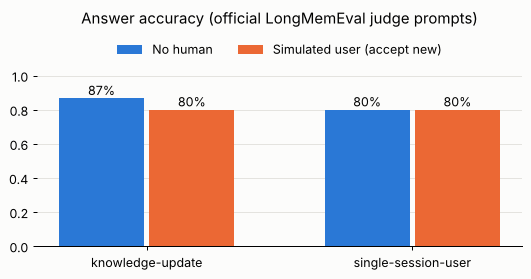

In [10]:
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 10})
BLUE, ORANGE, GRAY, GRID = "#2a78d6", "#eb6834", "#b9b8b2", "#e4e3df"

fig, ax = plt.subplots(figsize=(6, 3.2))
types = ["knowledge-update", "single-session-user"]
nh = [qa[qa.type == t].correct_no_human.mean() for t in types]
su = [qa[qa.type == t].correct_with_human.mean() for t in types]
x = range(len(types))
b1 = ax.bar([i - 0.17 for i in x], nh, 0.32, color=BLUE, label="No human")
b2 = ax.bar([i + 0.17 for i in x], su, 0.32, color=ORANGE, label="Simulated user (accept new)")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{b.get_height():.0%}", ha="center")
ax.set_xticks(list(x)); ax.set_xticklabels(types); ax.set_ylim(0, 1.1)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.15))
ax.set_title("Answer accuracy (official LongMemEval judge prompts)", pad=28)
plt.tight_layout(); plt.show()

### What happened at the turn where the user's information changed

Example updates that recorded the previous value:
   [2023/05/26] User has a language exchange session with tutor Maria this week on Thursday (previously unspecified day).
   [2023/04/30] User's mom now uses the same grocery list app as the user (previously still using a paper list).
   [2023/09/30] User has been following a daily tidying routine for 4 weeks (previously 3 weeks).
   [2023/08/15] User has a spare screwdriver for cleaning laptop fans (previously needed one).
   [2023/07/30] User plays tennis with friends at the local park every other week on Sunday (previously weekly sessions).
   [2023/09/30] User's goal is to reach level 150 in Apex Legends (previously 100).
   [2023/05/28] User's current Instagram follower count is 1300 (previously 1250).


,questions,answers_correct
update_turn_handling,,
silent overwrite,8,8
kept both (added),3,2
asked user (conflict),2,1
missed / skipped,2,2


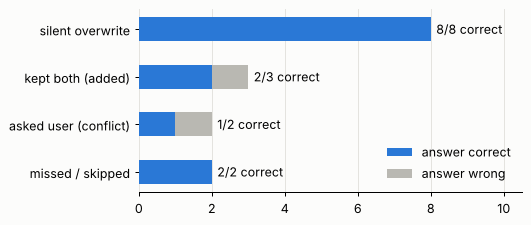

In [11]:
ku = qa[qa.type == "knowledge-update"]
handling = (ku.groupby("update_turn_handling")
              .agg(questions=("question_id", "count"), answers_correct=("correct_no_human", "sum"))
              .sort_values("questions", ascending=False))
display(handling)

fig, ax = plt.subplots(figsize=(6, 2.6))
labels = list(handling.index)[::-1]
tot = handling.questions[labels].values; cor = handling.answers_correct[labels].values
ax.barh(labels, cor, 0.5, color=BLUE, label="answer correct")
ax.barh(labels, tot - cor, 0.5, left=cor, color=GRAY, label="answer wrong")
for i, (t, c) in enumerate(zip(tot, cor)): ax.text(t + 0.15, i, f"{c}/{t} correct", va="center")
ax.set_xlim(0, max(tot) + 2.5); ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

print("Example updates that recorded the previous value:")
for t in ku[ku.question_id != "e66b632c"].retrieved_no_human:   # e66b632c: its 26:15 was invented (Part 5)
    for mem in t.split(" || "):
        if "(previously" in mem and len(mem) < 120:
            print("  ", mem)
            break

### How often each decision was taken
Parsed from the trace: one decision per extracted candidate memory.

In [12]:
trace = (RESULTS / "trace_lme_decision.md").read_text(encoding="utf-8")
blocks = re.split(r"\n### #\d+ · ", trace)
actions = Counter()
for b in blocks:
    if b.startswith("memory decision"):
        out = b.split("**→ OUTPUT:**", 1)[-1]
        m = re.search(r'"action":\s*"(\w+)"', out)
        if m: actions[m.group(1)] += 1
dec = pd.Series(actions).reindex(["add", "update", "skip", "conflict"]).rename("count").to_frame()
dec["share"] = (dec["count"] / dec["count"].sum()).map("{:.1%}".format)
dec

,count,share
add,231,67.2%
update,74,21.5%
skip,35,10.2%
conflict,4,1.2%


## Part 5 — Every question the system asked the user
Extracted from the trace: the existing memory, the new information, the model's reason, and what the user actually said. The **worth asking?** column is the author's manual judgement, using one rule: a question is worth asking only if the two memories cannot both be true *and* the conversation does not make clear which is right.

In [13]:
rows, sections = [], re.split(r"\n---\n\n## ", trace)
for sec in sections[1:]:
    header, body = sec.split("\n", 1)
    said = ""
    for c in re.split(r"\n### #\d+ · ", body):
        if c.startswith("extraction"):
            m = re.search(r"User said: (.*?)\nAssistant replied:", c, re.S)
            if m: said = m.group(1).strip()
        if c.startswith("memory decision") and '"action": "conflict"' in c.split("**→ OUTPUT:**")[-1]:
            new = re.search(r"NEW candidate memory: (.*?)\n", c).group(1)
            existing = re.search(r"EXISTING memories:\n(.*?)\n```", c, re.S).group(1).split("\n")
            v = json.loads(re.search(r"```text\n(.*?)\n```", c.split("**→ OUTPUT:**")[-1], re.S).group(1))
            target = next((l[3:] for l in existing if l.startswith(f"{v.get('target')}. ")), "?")
            rows.append({"question_id": header.split()[0], "existing_memory": target, "new_information": new,
                         "model_reason": v.get("reason"), "user_said": said[:160] + "..."})
asked = pd.DataFrame(rows)

VERDICTS = [  # (substring of the new information, verdict, why)
    ("terrain", "No", "User was describing the area, not a preference: an extraction error flagged as a conflict"),
    ("26 minutes 30", "YES", "The existing 26:15 was calculated by the system itself; asking lets the user fix an invented value"),
    ("five engineers", "Avoidable", "Clear change over time ('now'); a silent update keeping 'previously 4' would be better"),
    ("team of 5", "No", "Duplicate: the same question was asked again while the first was still pending"),
]
def verdict(new):
    for key, v, why in VERDICTS:
        if key in new: return pd.Series([v, why])
    return pd.Series(["(unlabelled)", ""])
asked[["worth_asking", "why"]] = asked.new_information.apply(verdict)
pd.set_option("display.max_colwidth", 120)
asked[["question_id", "existing_memory", "new_information", "worth_asking", "why"]]

,question_id,existing_memory,new_information,worth_asking,why
0,e66b632c,"User wants a 20-mile cycling route with moderate hills for a Saturday group ride, preferring a group bike ride in the local area with a mix of rolling and steeper hills, secondary roads with less traffic, an elevation gain of 500-1000 feet, scenic views, bike-friendly infrastructure, and a start/end point at the local park where they did a charity 5K run, and the route should avoid heavy traffic.",User's terrain preference is generally flat with some small hills.,No,"User was describing the area, not a preference: an extraction error flagged as a conflict"
1,e66b632c,User's 5K personal best is 26:15 (previously 27:45).,User's personal best 5K time is 26 minutes 30 seconds.,YES,The existing 26:15 was calculated by the system itself; asking lets the user fix an invented value
2,031748ae,"User leads a team of 4 engineers in their new role as Senior Software Engineer, with manager Rachel, totaling 5 people for the outing (previously 6 engineers and a manager).",User is a Senior Software Engineer who now leads a team of five engineers.,Avoidable,Clear change over time ('now'); a silent update keeping 'previously 4' would be better
3,031748ae,"User leads a team of 4 engineers in their new role as Senior Software Engineer, with manager Rachel, totaling 5 people for the outing (previously 6 engineers and a manager).",User is leading a team of 5 engineers.,No,Duplicate: the same question was asked again while the first was still pending


In [14]:
print(f"Questions asked to the user: {len(asked)} (in {asked.question_id.nunique()} of 30 questions)")
print("Asked on control (no-update) questions:", summary["control_questions_with_any_conflict"])
print(asked.worth_asking.value_counts().to_string())

Questions asked to the user: 4 (in 2 of 30 questions)
Asked on control (no-update) questions: 0
worth_asking
No           2
YES          1
Avoidable    1


## Part 6 — Error analysis
Each wrong answer is attributed to a pipeline stage by reading the trace.

In [15]:
STAGE = {
    "5a4f22c0": "management: 'now working at TechCorp' extracted, then SKIPPED as a duplicate",
    "031748ae": "management: pending conflict kept '4 engineers'; accepting new lost the history",
    "e66b632c": "naive human: accepting '26:30' erased '(previously 27:45)' that the question needed",
    "af8d2e46": "extraction: '7 shirts' generalised to 'wants to improve packing'",
    "8550ddae": "retrieval/reasoning: two lavender cocktail memories, model picked the wrong one",
    "1faac195": "reasoning: 'visit sister Emily in Denver' retrieved, model said it did not know",
}
wrong = qa[(qa.correct_no_human == 0) | (qa.correct_with_human == 0)].copy()
wrong["stage"] = wrong.question_id.map(STAGE)
wrong[["question_id", "type", "question", "gold", "correct_no_human", "correct_with_human", "stage"]]

,question_id,type,question,gold,correct_no_human,correct_with_human,stage
0,e66b632c,knowledge-update,What was my previous personal best time for the charity 5K run?,27 minutes and 45 seconds,1,0,naive human: accepting '26:30' erased '(previously 27:45)' that the question needed
9,5a4f22c0,knowledge-update,"What company is Rachel, an old colleague from my previous company, currently working at?",TechCorp,0,0,"management: 'now working at TechCorp' extracted, then SKIPPED as a duplicate"
13,031748ae,knowledge-update,How many engineers do I lead when I just started my new role as Senior Software Engineer? How many engineers do I lead now?,"When you just started your new role as Senior Software Engineer, you led 4 engineers. Now, you lead 5 engineers",0,0,management: pending conflict kept '4 engineers'; accepting new lost the history
16,af8d2e46,single-session-user,How many shirts did I pack for my 5-day trip to Costa Rica?,7,0,0,extraction: '7 shirts' generalised to 'wants to improve packing'
23,8550ddae,single-session-user,What type of cocktail recipe did I try last weekend?,lavender gin fizz,0,0,"retrieval/reasoning: two lavender cocktail memories, model picked the wrong one"
25,1faac195,single-session-user,Where does my sister Emily live?,Denver,0,0,"reasoning: 'visit sister Emily in Denver' retrieved, model said it did not know"


## Part 7 — Cost

In [16]:
t = summary["tokens"]
print(f"LLM calls : {summary['llm_calls']}")
print(f"tokens    : {t['prompt_tokens']:,} in / {t['completion_tokens']:,} out")
print(f"time      : {summary['minutes']} min")
print(f"cost      : ${summary['approx_cost_usd']}  (about Rs {summary['approx_cost_usd'] * 94:.0f})")

LLM calls : 669
tokens    : 379,865 in / 83,536 out
time      : 6.9 min
cost      : $0.0536  (about Rs 5)


## Conclusion
* Without a human, the pipeline answers **87%** of knowledge-update and **80%** of plain-recall questions (oracle setting, 15 each).
* It asks the user **rarely**: 4 questions in 30, and never on plain recall. But only **1 of 4** was worth asking, and that one caught a value the system had invented itself.
* Clear changes are best handled by **silent but visible updates that keep the previous value** (8/8 correct).
* A user who blindly accepts new information makes answers **worse**. Questions should come with context (source, reason, history) and a "both are true" option.